# Group 5.1 — Gaussian Efficiency Penalty

Compare **SmallGBMClassifier** with two fixed XGBoost configurations on uncontaminated Gaussian classification data, with training sizes up to **10,000**. Separately measure the statistical efficiency of the sample mean and median under Gaussian sampling.

Run all cells in order. Required installed packages: `smallgbm`, `xgboost`, `numpy`, `scipy`, `scikit-learn`, `joblib`, `threadpoolctl`, and `matplotlib`. No installation or source-code embedding is performed. Outputs are saved under `results/group51/`.

In [1]:
import csv
import json
import platform
import time
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from joblib import Parallel, delayed, parallel_config, cpu_count
from threadpoolctl import threadpool_limits
from smallgbm import SmallGBMClassifier
from xgboost import XGBClassifier

## 1. Fixed protocol and CPU budget

Twenty independent seeds; paired data for all models; nested training subsets within each seed; an independent 10,000-row test set per seed. No tuning, early stopping, clipping, label flips, or removal of extreme samples. A Gaussian distribution has natural tails: **uncontaminated** does not mean bounded.

Processes run independent seeds concurrently. XGBoost uses up to two threads inside each process. Do not switch to a shared-thread backend: SmallGBM 1.5.0 uses a process-global native random generator. Total requested CPU threads stay within the available budget. Timings under concurrent load are descriptive, not isolated speed benchmarks.

In [2]:
TRAIN_SIZES = (100, 200, 500, 1000, 2000, 5000, 10000)
SEEDS = (11, 29, 47, 71, 101, 131, 173, 211, 257, 307,
         353, 401, 457, 503, 557, 601, 653, 701, 751, 809)
N_TEST = 10000
D = 10
SEPARATION = 1.0  # norm of each class mean
MC_SIZES = (5, 10, 20, 30, 50, 100, 300, 1000, 3000, 10000)
MC_REPEATS = 5000
MC_SEED = 20261117
THREADS_PER_WORKER = min(2, cpu_count())
N_WORKERS = min(4, max(1, (cpu_count() - 1) // THREADS_PER_WORKER))

assert max(TRAIN_SIZES) <= 10000 and max(MC_SIZES) <= 10000
assert len(SEEDS) >= 2 and len(set(SEEDS)) == len(SEEDS)
assert tuple(sorted(TRAIN_SIZES)) == TRAIN_SIZES and D >= 3
assert N_WORKERS * THREADS_PER_WORKER <= cpu_count()

OUT = Path("results/group51") / datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
OUT.mkdir(parents=True, exist_ok=False)
(OUT / "predictions").mkdir()
MODELS = ("SmallGBM", "XGBoost-200", "XGBoost-50")
METRICS = ("auc", "accuracy", "log_loss", "fit_seconds")

def make_model(name, seed):
    if name == "SmallGBM":
        return SmallGBMClassifier(random_state=seed)
    common = dict(objective="binary:logistic", eval_metric="logloss",
                  tree_method="hist", max_depth=3, device="cpu",
                  n_jobs=THREADS_PER_WORKER, random_state=seed)
    if name == "XGBoost-200":
        return XGBClassifier(**common, n_estimators=200, learning_rate=0.05)
    if name == "XGBoost-50":
        return XGBClassifier(**common, n_estimators=50, learning_rate=0.1,
                             colsample_bytree=0.5)
    raise ValueError(name)

def write_csv(path, rows):
    if not rows:
        return
    with Path(path).open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

packages = ("numpy", "scipy", "scikit-learn", "smallgbm", "xgboost",
            "joblib", "threadpoolctl", "matplotlib")
nominal = dict(n_estimators=50, max_depth=3, learning_rate=0.1, colsample_bytree=0.5)
assert all(make_model("SmallGBM", SEEDS[0]).get_params()[k] == v for k, v in nominal.items()), \
    "SmallGBM defaults changed; review the nominally matched XGBoost-50 configuration."

def save_protocol():
    # XGBoost's missing-value parameter is NaN; record it as text in valid JSON.
    def portable(value):
        if isinstance(value, dict):
            return {k: portable(v) for k, v in value.items()}
        if isinstance(value, (list, tuple)):
            return [portable(v) for v in value]
        if isinstance(value, float) and not np.isfinite(value):
            return str(value)
        return value
    (OUT / "protocol.json").write_text(
        json.dumps(portable(protocol), indent=2, allow_nan=False), encoding="utf-8")

protocol = dict(
    train_sizes=TRAIN_SIZES, seeds=SEEDS, n_test=N_TEST, d=D,
    separation=SEPARATION, mc_sizes=MC_SIZES, mc_repeats=MC_REPEATS,
    mc_seed=MC_SEED, n_workers=N_WORKERS, threads_per_worker=THREADS_PER_WORKER,
    versions={name: version(name) for name in packages}, python=platform.python_version(),
    platform=platform.platform(),
    models={name: make_model(name, SEEDS[0]).get_params() for name in MODELS},
    primary_metric="ROC-AUC; paired XGBoost-200 minus SmallGBM",
    data="Y ~ Bernoulli(0.5); X | Y ~ N((2Y-1)*mu, I); ||mu||=separation",
    intervals="Pointwise 95% t intervals over seeds; paired for AUC differences",
)
save_protocol()
print(f"CPU budget: {N_WORKERS} processes x {THREADS_PER_WORKER} threads")
print(f"Planned fits: {len(SEEDS) * len(TRAIN_SIZES) * len(MODELS)}")
print("Package versions:", protocol["versions"])
print("Output:", OUT)

CPU budget: 4 processes x 2 threads
Planned fits: 420
Package versions: {'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'smallgbm': '1.5.0', 'xgboost': '3.4.1', 'joblib': '1.6.0', 'threadpoolctl': '3.8.0', 'matplotlib': '3.11.2'}
Output: results/group51/20261117-105437-390406


## 2. Clean Gaussian classification

Generate equally likely classes with $X\mid Y\sim N((2Y-1)\mu,I_{10})$, where $\mu$ has three nonzero coordinates and $\|\mu\|=1$. Class overlap is intrinsic, not label corruption. The population Bayes accuracy is $\Phi(1)$ and AUC is $\Phi(\sqrt{2})$.

SmallGBM uses its installed defaults. XGBoost-200 uses a fixed 200-tree configuration; XGBoost-50 shares SmallGBM's nominal tree count, depth, learning rate, and feature fraction. These are **fixed configurations**, not XGBoost defaults or a full component ablation. The models still differ in split search, leaf updates, shrinkage, and other settings.

In [3]:
def gaussian_data(seed):
    train_seed, test_seed = np.random.SeedSequence(seed).spawn(2)
    mu = np.zeros(D)
    mu[:3] = np.array([1.0, 0.75, -0.5])
    mu *= SEPARATION / np.linalg.norm(mu)

    def draw(n, stream):
        rng = np.random.default_rng(stream)
        y = rng.integers(0, 2, size=n)
        X = rng.normal(size=(n, D)) + (2 * y[:, None] - 1) * mu
        return np.ascontiguousarray(X), y

    X, y = draw(max(TRAIN_SIZES), train_seed)
    Xt, yt = draw(N_TEST, test_seed)
    return X, y, Xt, yt, mu


def seed_smallgbm(seed):
    # SmallGBM 1.5.0 seeds NumPy, but its C backend also uses rand().
    # This private hook must run inside the same process as the subsequent fit.
    import ctypes
    from smallgbm import tree as gbm_tree
    try:
        seed_c = gbm_tree._lib.srand
    except AttributeError as exc:
        raise RuntimeError("Review native RNG seeding for this SmallGBM build.") from exc
    seed_c.argtypes = [ctypes.c_uint]
    seed_c.restype = None
    seed_c(int(seed))


def fit_predict(name, seed, X, y, Xt):
    model = make_model(name, seed)
    with threadpool_limits(limits=THREADS_PER_WORKER):
        if name == "SmallGBM":
            seed_smallgbm(seed)
        start = time.perf_counter()
        model.fit(X, y)
        fit_seconds = time.perf_counter() - start
        p = np.asarray(model.predict_proba(Xt)[:, 1])
    assert p.shape == (len(Xt),) and np.isfinite(p).all()
    assert np.all((p >= 0) & (p <= 1))
    return p, fit_seconds


def reproducibility_probe():
    rng = np.random.default_rng(91427)
    X = rng.normal(size=(180, D))
    y = (X[:, 0] + X[:, 1] > 0).astype(int)
    Xt = rng.normal(size=(70, D))
    return fit_predict("SmallGBM", 991, X, y, Xt)[0]

# Compare sequential repetitions with repetitions in separate workers.
a, b = reproducibility_probe(), reproducibility_probe()
with parallel_config(backend="loky", n_jobs=N_WORKERS,
                     inner_max_num_threads=THREADS_PER_WORKER):
    probes = Parallel()(delayed(reproducibility_probe)() for _ in range(2))
assert all(np.array_equal(a, p) for p in [b, *probes]), "Native RNG is not reproducible."
print("SmallGBM sequential/parallel reproducibility check passed.")
print(f"Population Bayes AUC: {norm.cdf(np.sqrt(2) * SEPARATION):.4f}; "
      f"accuracy: {norm.cdf(SEPARATION):.4f}")

SmallGBM sequential/parallel reproducibility check passed.
Population Bayes AUC: 0.9214; accuracy: 0.8413


In [4]:
def run_seed(seed, output_dir):
    output_dir = Path(output_dir)
    X, y, Xt, yt, mu = gaussian_data(seed)
    np.savez_compressed(output_dir / "predictions" / f"data_{seed}.npz",
                        X_train=X, y_train=y, X_test=Xt, y_test=yt, mu=mu)
    rows = []
    for n in TRAIN_SIZES:
        assert np.unique(y[:n]).size == 2 and np.unique(yt).size == 2
        for name in MODELS:
            row = dict(seed=seed, n=n, model=name, train_positive=int(y[:n].sum()),
                       test_positive=int(yt.sum()), status="ok", error="",
                       auc=None, accuracy=None, log_loss=None, fit_seconds=None)
            try:
                p, seconds = fit_predict(name, seed, X[:n], y[:n], Xt)
                row.update(auc=float(roc_auc_score(yt, p)),
                           accuracy=float(accuracy_score(yt, p > 0.5)),
                           log_loss=float(log_loss(yt, np.column_stack((1-p, p)), labels=[0, 1])),
                           fit_seconds=seconds)
                np.savez_compressed(output_dir / "predictions" / f"{seed}_{n}_{name}.npz", p=p)
            except Exception as exc:
                row.update(status="error", error=f"{type(exc).__name__}: {exc}")
            rows.append(row)
    return rows

rows = []
start = time.perf_counter()
with parallel_config(backend="loky", n_jobs=N_WORKERS,
                     inner_max_num_threads=THREADS_PER_WORKER):
    batches = Parallel(return_as="generator_unordered")(
        delayed(run_seed)(seed, str(OUT)) for seed in SEEDS)
    for batch in batches:
        rows.extend(batch)
        rows.sort(key=lambda r: (r["seed"], r["n"], r["model"]))
        write_csv(OUT / "runs.csv", rows)
        print(f"Completed {len(rows)}/{len(SEEDS)*len(TRAIN_SIZES)*len(MODELS)} fits", flush=True)
elapsed = time.perf_counter() - start
failed = [r for r in rows if r["status"] != "ok"]
assert len(rows) == len(SEEDS) * len(TRAIN_SIZES) * len(MODELS)
assert not failed, f"{len(failed)} failed fits. Inspect runs.csv before interpreting results."
protocol["wall_seconds"] = elapsed
save_protocol()
print(f"Completed without errors in {elapsed:.1f} seconds.")

Completed 21/420 fits
Completed 42/420 fits
Completed 63/420 fits
Completed 84/420 fits
Completed 105/420 fits
Completed 126/420 fits
Completed 147/420 fits
Completed 168/420 fits
Completed 189/420 fits
Completed 210/420 fits
Completed 231/420 fits
Completed 252/420 fits
Completed 273/420 fits
Completed 294/420 fits
Completed 315/420 fits
Completed 336/420 fits
Completed 357/420 fits
Completed 378/420 fits
Completed 399/420 fits
Completed 420/420 fits
Completed without errors in 9.1 seconds.


## 3. Learning curves and paired comparisons

Bands are pointwise 95% confidence intervals for the mean over independent train/test seeds. They are not simultaneous confidence bands. The same test set is reused across sizes within each seed. A positive paired AUC difference favors XGBoost. Do not infer an exact crossover between unmeasured sizes or generalize this one distribution to all clean datasets.

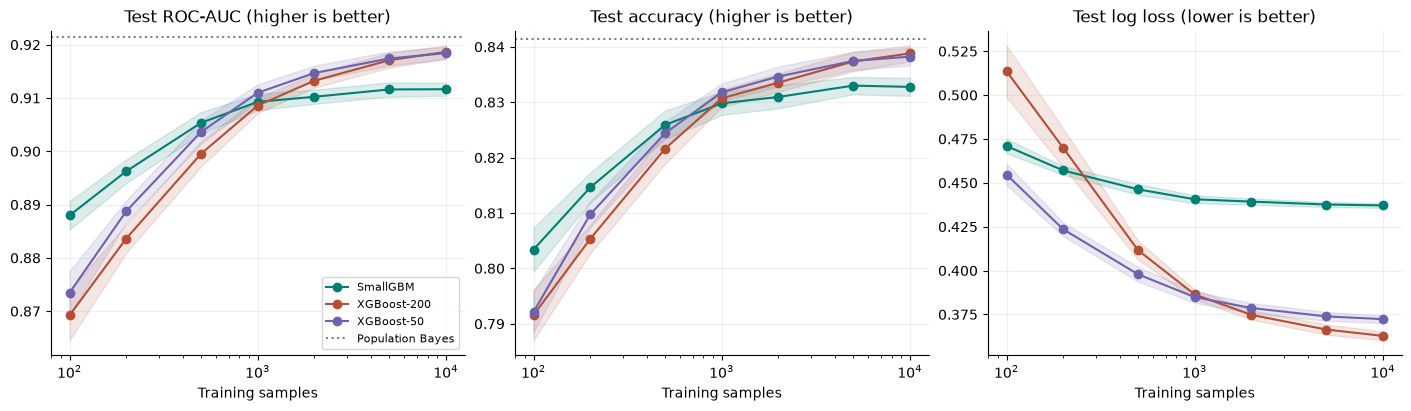

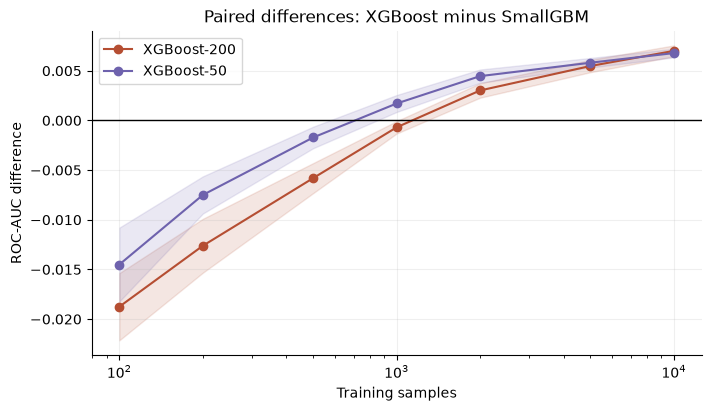

Mean test AUC (20 independent seeds by default):
     n          SmallGBM       XGBoost-200        XGBoost-50
   100           0.88798           0.86923           0.87347
   200           0.89625           0.88363           0.88874
   500           0.90535           0.89954           0.90363
  1000           0.90927           0.90858           0.91098
  2000           0.91023           0.91324           0.91469
  5000           0.91160           0.91708           0.91741
 10000           0.91165           0.91865           0.91842


In [5]:
def mean_ci(values):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all() and len(values) >= 2
    mean = float(values.mean())
    half = float(t.ppf(0.975, len(values)-1) * values.std(ddof=1) / np.sqrt(len(values)))
    return mean, mean-half, mean+half

summary = []
for n in TRAIN_SIZES:
    for name in MODELS:
        selected = [r for r in rows if r["n"] == n and r["model"] == name]
        assert len(selected) == len(SEEDS)
        for metric in METRICS:
            mean, lo, hi = mean_ci([r[metric] for r in selected])
            summary.append(dict(n=n, model=name, metric=metric, mean=mean,
                                ci_low=lo, ci_high=hi, seeds=len(selected)))
write_csv(OUT / "summary.csv", summary)

lookup = {(r["seed"], r["n"], r["model"]): r for r in rows}
paired = []
for name in MODELS[1:]:
    for n in TRAIN_SIZES:
        delta = [lookup[s, n, name]["auc"] - lookup[s, n, "SmallGBM"]["auc"] for s in SEEDS]
        mean, lo, hi = mean_ci(delta)
        paired.append(dict(n=n, comparison=f"{name} minus SmallGBM", mean=mean,
                           ci_low=lo, ci_high=hi, seeds=len(delta)))
write_csv(OUT / "paired_auc.csv", paired)

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
colors = {"SmallGBM": "#007f73", "XGBoost-200": "#b54e32", "XGBoost-50": "#6e62ad"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, metric, title in zip(axes, ("auc", "accuracy", "log_loss"),
                             ("Test ROC-AUC (higher is better)", "Test accuracy (higher is better)",
                              "Test log loss (lower is better)")):
    for name in MODELS:
        vals = [r for r in summary if r["model"] == name and r["metric"] == metric]
        ax.plot(TRAIN_SIZES, [r["mean"] for r in vals], "o-", color=colors[name], label=name)
        ax.fill_between(TRAIN_SIZES, [r["ci_low"] for r in vals], [r["ci_high"] for r in vals],
                        color=colors[name], alpha=0.14)
    if metric in ("auc", "accuracy"):
        bound = norm.cdf(SEPARATION * (np.sqrt(2) if metric == "auc" else 1))
        ax.axhline(bound, color="gray", ls=":", label="Population Bayes")
    ax.set(xscale="log", xlabel="Training samples", title=title)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"classification_learning_curves.{ext}", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for name in MODELS[1:]:
    vals = [r for r in paired if r["comparison"] == f"{name} minus SmallGBM"]
    ax.plot(TRAIN_SIZES, [r["mean"] for r in vals], "o-", label=name, color=colors[name])
    ax.fill_between(TRAIN_SIZES, [r["ci_low"] for r in vals], [r["ci_high"] for r in vals],
                    alpha=0.14, color=colors[name])
ax.axhline(0, color="black", lw=1)
ax.set(xscale="log", xlabel="Training samples", ylabel="ROC-AUC difference",
       title="Paired differences: XGBoost minus SmallGBM")
ax.legend(); ax.grid(alpha=0.2)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"paired_auc.{ext}", dpi=180)
plt.show()

print("Mean test AUC (20 independent seeds by default):")
print(f"{'n':>6}" + "".join(f"{name:>18}" for name in MODELS))
for n in TRAIN_SIZES:
    values = [next(r["mean"] for r in summary
                   if r["n"] == n and r["model"] == name and r["metric"] == "auc") for name in MODELS]
    print(f"{n:6d}" + "".join(f"{v:18.5f}" for v in values))

## 4. Direct Gaussian mean-versus-median diagnostic

For independent $Z_i\sim N(0,1)$, estimate the common population mean/median $0$. The sample mean has MSE $1/n$; the sample median has asymptotic MSE $\pi/(2n)$. Thus its asymptotic relative efficiency is $2/\pi\approx0.637$. Simulate paired estimates from identical samples in memory-bounded batches. The bands below quantify Monte Carlo uncertainty (paired delta-method 95% intervals for the MSE ratio).

This demonstrates a **Gaussian location-estimation penalty**. It does not prove the cause of a classifier performance difference: binary boosting residuals are not Gaussian, and SmallGBM uses a median only in small leaves. A leaf-estimator ablation would be needed for causal attribution.

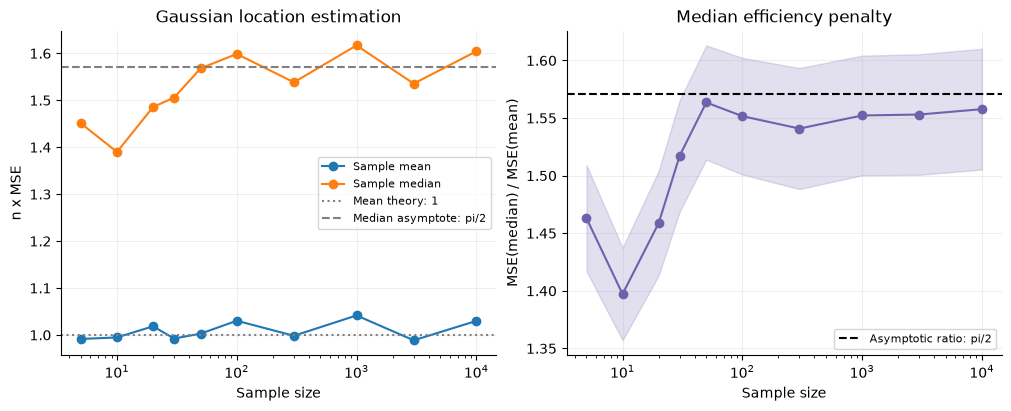

At n=10000: median/mean MSE ratio=1.558 (Monte Carlo 95% CI 1.505–1.610); asymptotic target=1.571.
All results saved to results/group51/20261117-105437-390406


In [6]:
def gaussian_efficiency(n):
    rng = np.random.default_rng(np.random.SeedSequence([MC_SEED, n]))
    mean_error = np.empty(MC_REPEATS)
    median_error = np.empty(MC_REPEATS)
    for begin in range(0, MC_REPEATS, 128):
        end = min(begin + 128, MC_REPEATS)
        z = rng.normal(size=(end-begin, n))
        mean_error[begin:end] = z.mean(axis=1) ** 2
        median_error[begin:end] = np.median(z, axis=1) ** 2
    m1, m2 = mean_error.mean(), median_error.mean()
    ratio = m2 / m1
    influence = (median_error - ratio * mean_error) / m1
    half = norm.ppf(0.975) * influence.std(ddof=1) / np.sqrt(MC_REPEATS)
    np.savez_compressed(OUT / f"location_errors_{n}.npz",
                        mean_squared_error=mean_error, median_squared_error=median_error)
    return dict(n=n, repeats=MC_REPEATS, mean_mse=float(m1), median_mse=float(m2),
                ratio=float(ratio), ci_low=float(ratio-half), ci_high=float(ratio+half))

with parallel_config(backend="loky", n_jobs=N_WORKERS,
                     inner_max_num_threads=THREADS_PER_WORKER):
    efficiency = Parallel()(delayed(gaussian_efficiency)(n) for n in MC_SIZES)
write_csv(OUT / "gaussian_location_efficiency.csv", efficiency)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
n = np.array(MC_SIZES)
axes[0].plot(n, [r["n"]*r["mean_mse"] for r in efficiency], "o-", label="Sample mean")
axes[0].plot(n, [r["n"]*r["median_mse"] for r in efficiency], "o-", label="Sample median")
axes[0].axhline(1, color="gray", ls=":", label="Mean theory: 1")
axes[0].axhline(np.pi/2, color="gray", ls="--", label="Median asymptote: pi/2")
axes[0].set(xscale="log", xlabel="Sample size", ylabel="n x MSE", title="Gaussian location estimation")
axes[0].legend(fontsize=8)
axes[1].plot(n, [r["ratio"] for r in efficiency], "o-", color="#6e62ad")
axes[1].fill_between(n, [r["ci_low"] for r in efficiency], [r["ci_high"] for r in efficiency],
                     color="#6e62ad", alpha=0.2)
axes[1].axhline(np.pi/2, color="black", ls="--", label="Asymptotic ratio: pi/2")
axes[1].set(xscale="log", xlabel="Sample size", ylabel="MSE(median) / MSE(mean)",
            title="Median efficiency penalty")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"gaussian_efficiency.{ext}", dpi=180)
plt.show()
last = efficiency[-1]
print(f"At n={last['n']}: median/mean MSE ratio={last['ratio']:.3f} "
      f"(Monte Carlo 95% CI {last['ci_low']:.3f}–{last['ci_high']:.3f}); "
      f"asymptotic target={np.pi/2:.3f}.")
print("All results saved to", OUT)

## Reporting

Report the full learning curves, paired AUC differences, all seeds, package versions, and fixed model configurations. Report a lack of crossover if none is observed. The location-estimation result supports the familiar robustness/efficiency trade-off; it does not establish that a median leaf causes a whole-model loss, that XGBoost always wins on clean data, or that one synthetic task represents real datasets.

Sources: [Gaussian median asymptotics (Williams College)](https://web.williams.edu/Mathematics/sjmiller/public_html/probabilitylifesaver/supplementalchap_mediantheoremandorderstatistics.pdf); [joblib parallel configuration](https://joblib.readthedocs.io/en/stable/generated/joblib.parallel_config.html); [SmallGBM implementation](https://github.com/nsdmlk/SmallGBM).